<a href="https://colab.research.google.com/github/sawantarya232-blip/Deep-Learning/blob/main/Assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q torch torchvision scikit-learn matplotlib

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import gc

from torch.utils.data import DataLoader, Subset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

torch.manual_seed(42)

train_indices = torch.randperm(len(train_data))[:2000].tolist()
test_indices = torch.randperm(len(test_data))[:500].tolist()

train_subset = Subset(train_data, train_indices)
test_subset = Subset(test_data, test_indices)

train_loader = DataLoader(train_subset, batch_size=16, shuffle=True, num_workers=0)
test_loader = DataLoader(test_subset, batch_size=16, shuffle=False, num_workers=0)

classes = train_data.classes

print("Training images:", len(train_subset))
print("Testing images:", len(test_subset))
print("Classes:", classes)

100%|██████████| 170M/170M [52:37<00:00, 54.0kB/s]


Training images: 2000
Testing images: 500
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


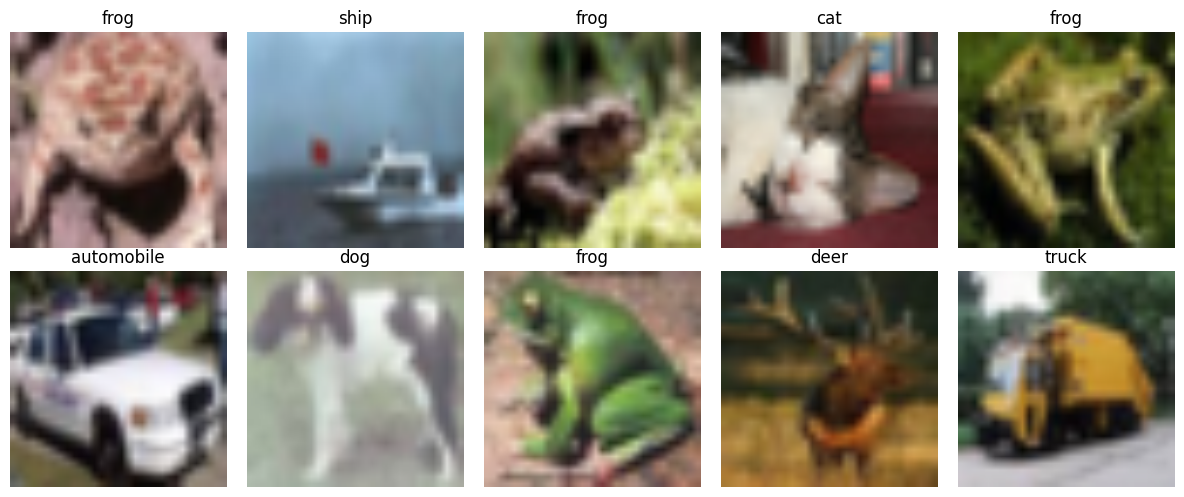

In [4]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    img = images[i].permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = np.clip(img * std + mean, 0, 1)

    ax.imshow(img)
    ax.set_title(classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:
def load_model(model_name, num_classes=10):

    if model_name == "AlexNet":
        model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
        for param in model.features.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, num_classes
        )

    elif model_name == "VGG16":
        model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
        for param in model.features.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, num_classes
        )

    elif model_name == "ResNet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        for param in model.parameters():
            param.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "EfficientNetB0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        for param in model.parameters():
            param.requires_grad = False
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, num_classes
        )

    return model.to(device)

In [8]:
model_names = ["AlexNet", "VGG16", "ResNet50", "EfficientNetB0"]

results = []

for name in model_names:
    print("\nTraining:", name)

    model = load_model(name)

    # Freeze all layers
    for param in model.parameters():
        param.requires_grad = False

    # Train only the final classification layer
    if name in ["AlexNet", "VGG16"]:
        head = model.classifier[6]
    elif name == "ResNet50":
        head = model.fc
    else:
        head = model.classifier[1]

    for param in head.parameters():
        param.requires_grad = True

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(head.parameters(), lr=0.001)

    start_time = time.time()

    for epoch in range(2):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        print(
            f"Epoch {epoch + 1}/2 | "
            f"Loss: {total_loss / len(train_loader):.4f} | "
            f"Accuracy: {100 * correct / total:.2f}%"
        )

    training_time = time.time() - start_time

    # Evaluate model
    model.eval()
    y_true = []
    y_pred = []

    inference_start = time.time()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    inference_time = time.time() - inference_start

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2),
        "Training Time (s)": round(training_time, 2),
        "Inference Time (s)": round(inference_time, 2)
    })

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

    del model, optimizer, criterion
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Training: AlexNet
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 179MB/s]


Epoch 1/2 | Loss: 1.0603 | Accuracy: 62.65%
Epoch 2/2 | Loss: 0.6323 | Accuracy: 78.30%
AlexNet Accuracy: 77.0 %

Training: VGG16
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 88.9MB/s]


Epoch 1/2 | Loss: 0.9791 | Accuracy: 64.85%
Epoch 2/2 | Loss: 0.5821 | Accuracy: 80.30%
VGG16 Accuracy: 78.4 %

Training: ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 116MB/s]


Epoch 1/2 | Loss: 1.6105 | Accuracy: 49.50%
Epoch 2/2 | Loss: 1.0536 | Accuracy: 69.20%
ResNet50 Accuracy: 72.2 %

Training: EfficientNetB0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 186MB/s]


Epoch 1/2 | Loss: 1.7070 | Accuracy: 50.05%
Epoch 2/2 | Loss: 1.1667 | Accuracy: 66.90%
EfficientNetB0 Accuracy: 71.0 %


In [9]:
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

         Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Training Time (s)  Inference Time (s)
       AlexNet          77.0          77.18       77.69         76.74              10.43                1.03
         VGG16          78.4          79.11       78.55         78.28              24.23                2.89
      ResNet50          72.2          72.89       72.38         71.75              20.51                2.39
EfficientNetB0          71.0          71.92       71.62         70.88              10.86                1.29


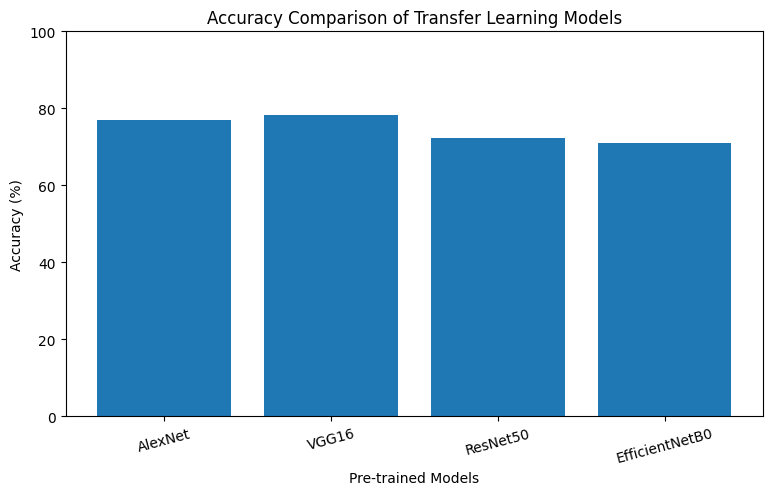

In [10]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["Accuracy (%)"])
plt.xlabel("Pre-trained Models")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison of Transfer Learning Models")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()

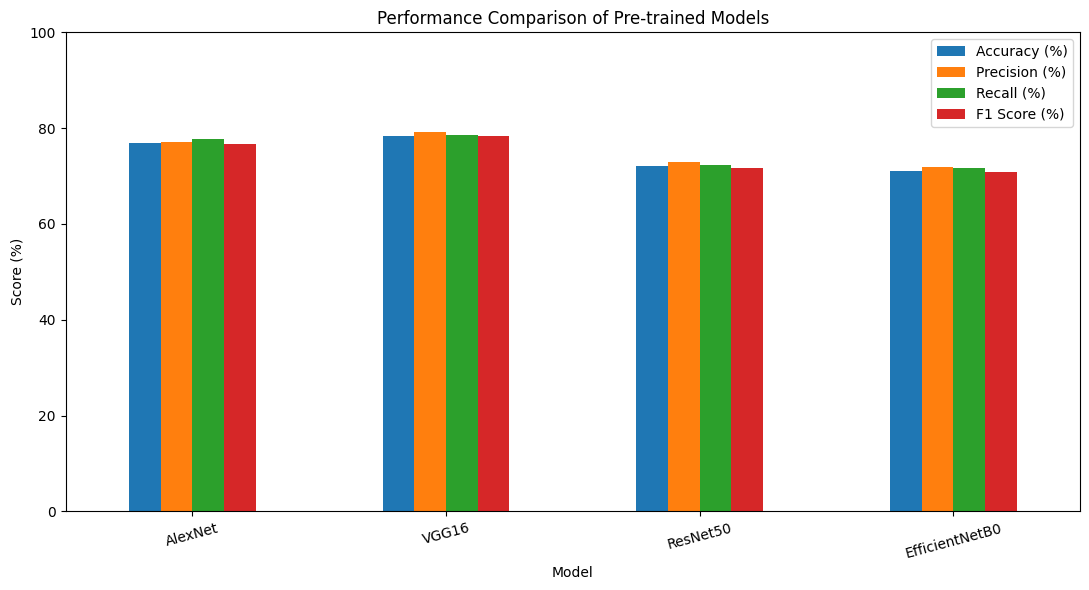

In [11]:
metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 Score (%)"]

results_df.plot(
    x="Model",
    y=metrics,
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Pre-trained Models")
plt.ylabel("Score (%)")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [12]:
best_model = results_df.loc[results_df["Accuracy (%)"].idxmax()]

print("Best Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy (%)"], "%")
print("F1 Score:", best_model["F1 Score (%)"], "%")

Best Model: VGG16
Accuracy: 78.4 %
F1 Score: 78.28 %
